# Análisis de los experimentos del gemelo ACO

Este notebook explica **cómo funciona un ensayo** del gemelo y después responde tres preguntas con los experimentos en lote (`../experimentos/datos/`):

1. **¿Qué aporta cada modo de la madre** (ausente, pista de baile, rescate, difusión) en el mundo L del plano y en mundos con obstáculos aleatorios?
2. **¿Cuánto cuesta en la red?** Tamaño de cada mensaje frente al límite de ESP-NOW y tráfico por familia de mensajes.
3. **¿Reduce el rescate la varianza del tiempo de convergencia?** Es la hipótesis de `referencia/resumen.pdf`.

| Sección | Qué muestra |
|---|---|
| 1. Cómo funciona un ensayo | Una corrida comentada: el mundo, la ruta óptima y las fases |
| 2. Feromona y trazos | Dónde dejaron rastro las agentes, sin madre y con madre |
| 3. Lo que sabe la madre | Cómo se arma el mapa de la madre con los `FRAGMENTO` |
| 4. Los modos de la madre | Convergencia, tiempo y costo de red de los 4 modos (240 ensayos) |
| 5. Costo de red | Tamaño de los mensajes y tráfico por familia |
| 6. El rescate | El umbral de rescate y la varianza del tiempo |
| 7. Conclusiones | Calculadas a partir de los datos |

**Para regenerar los datos** (desde `gemelo/`, con el Python del entorno `aco-gemelo`):

```
python -X utf8 -m aco_gemelo experimentos --plan experimentos/modos.yaml
python -X utf8 -m aco_gemelo experimentos --plan experimentos/rescate.yaml
```

Las secciones 1 a 3 corren dos ensayos en vivo (unos segundos). Las conclusiones del final **se calculan a partir de los datos**: si se vuelven a correr los experimentos, se actualizan solas. Cada figura se guarda en `figuras/` y lleva debajo un **"Qué mirar"**.

### Glosario

- **Tick:** un paso del reloj del ensayo. En cada tick cada agente percibe, decide y actúa una vez.
- **Asentarse:** una agente que terminó sus viajes de ida y vuelta y se queda en la meta.
- **Convergencia** (decisión G1): todas las agentes se asientan **y** la verificadora llega a la meta siguiendo solo el rastro de feromona.
- **Verificadora:** una agente que sale al final, solo explota el rastro y no puede volver sobre sus pasos. Si llega, el rastro sirve como camino.
- **Razón:** largo de la ruta verificada ÷ largo de la ruta óptima (1 = óptima).
- **Madre:** el nodo del edge (la Raspberry Pi del plano). No se mueve; recibe informes y, según su modo, recluta, difunde rutas o rescata.
- **Rezagada:** una agente con experiencia menor que el umbral de rescate × el promedio de la colonia; la madre en modo rescate le envía una ruta.
- **Δt:** cada cuántos ticks actúa la madre (y cada cuántos informa cada agente su estado).
- **Familias de mensajes:** 0 = mundo ↔ agente (sensor y actuador), 1 = agente ↔ agente, 2 = agente → madre, 3 = madre → agentes (`PROTOCOLO.md`).


In [1]:
import sys
from dataclasses import replace
from pathlib import Path

import matplotlib.pyplot as plt
from matplotlib import animation
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.patches import Rectangle
import numpy as np
import pandas as pd
from scipy.stats import fisher_exact, levene, mannwhitneyu

sys.path.insert(0, str(Path("..").resolve()))  # el paquete del gemelo
from aco_gemelo.config import cargar, config_ensayo, crear_mundo
from aco_gemelo.motor import Simulacion
from aco_gemelo.protocolo.tamanos import LIMITE_ESP_NOW, tamanos
from aco_gemelo.visual import COLORES_HEX as PLANO
%matplotlib inline
# (aco_gemelo.visual fija el modo sin pantalla "Agg"; la línea de arriba vuelve a mostrar las figuras aquí)

DATOS = Path("..") / "experimentos" / "datos"
FIGURAS = Path("figuras")
FIGURAS.mkdir(exist_ok=True)

# Colores del plano de ensayo (bosquejo/)
COLOR = {"ausente": "#94a3b8", "pista_de_baile": "#15803d", "rescate": "#d97706", "difusion": "#2563eb"}
MODOS = ["ausente", "pista_de_baile", "rescate", "difusion"]
NOMBRE = {"ausente": "Sin madre", "pista_de_baile": "Pista de baile", "rescate": "Rescate (umbral 0,5)",
          "difusion": "Difusión"}
ESCENARIOS = {"L": "Mundo L (plano)", "aleatorio": "Mundo aleatorio"}
plt.rcParams.update({"figure.dpi": 100, "axes.spines.top": False, "axes.spines.right": False})


def leer(plan):
    """Todos los ensayos de un plan (una fila por semilla) y su resumen."""
    carpeta = DATOS / plan
    ensayos = pd.concat([pd.read_csv(p) for p in sorted(carpeta.glob("*.csv")) if p.name != "resumen.csv"],
                        ignore_index=True)
    return ensayos, pd.read_csv(carpeta / "resumen.csv")


modos, resumen_modos = leer("modos")
rescate, resumen_rescate = leer("rescate")
print(f"modos: {len(modos)} ensayos · rescate: {len(rescate)} ensayos")

modos: 240 ensayos · rescate: 240 ensayos


## 1. Cómo funciona un ensayo

Antes de las estadísticas, **una sola corrida** con la configuración por defecto (`configs/default.yaml`): mundo L del plano, 6 agentes, 10 viajes cada una, evaporación ρ = 0,01.

**Regla de selección, fijada antes de ver el resultado:** la semilla es la de `default.yaml` (2026), sea cual sea el resultado; no se buscó un ensayo "bonito". Se corre dos veces sobre el mismo mundo y la misma semilla: **sin madre** y **con la madre en modo difusión**. Difusión y rescate son los dos modos en que la madre guarda un mapa del mundo (lo que muestra la sección 3); se usa difusión porque es el que además lo comparte con las agentes.

Un ensayo tiene tres fases:

1. **Colonia:** las agentes salen del nido (I) una por tick, buscan la meta (F) y, en cada vuelta al nido, depositan feromona en la ruta que recorrieron (sin bucles). Tras 10 viajes se asientan en la meta.
2. **Verificación:** cuando todas se asentaron, sale la verificadora y sigue solo el rastro.
3. **Cierre:** el motor difunde `FIN` con el motivo (verificada, falló la verificadora, límite o abortado).

In [2]:
BASE = cargar(Path("..") / "configs" / "default.yaml")
SEMILLA = BASE["semilla"]


def correr(modo):
    """Un ensayo de default.yaml con el modo de madre dado, registrando todo tick a tick."""
    datos = {**BASE, "madre": {**BASE["madre"], "modo": modo}}
    mundo = crear_mundo(datos)
    return mundo, Simulacion(mundo, replace(config_ensayo(datos), registrar=True)).correr()


MUNDO, SIN = correr("ausente")
_, CON = correr("difusion")
OPTIMA = MUNDO.bfs()
N_AGENTES = BASE["ensayo"]["n_agentes"]
for nombre, r in (("Sin madre", SIN), ("Con madre (difusión)", CON)):
    print(f"{nombre}: {r.motivo} · fase colonia {r.ticks_asentadas} ticks · verificación "
          f"{r.ticks_total - r.ticks_asentadas} ticks · ruta {r.largo_verificado} movimientos "
          f"(óptima {r.largo_optimo}; razón {r.largo_verificado / r.largo_optimo:.2f})")

Sin madre: verificada · fase colonia 603 ticks · verificación 16 ticks · ruta 15 movimientos (óptima 8; razón 1.88)
Con madre (difusión): verificada · fase colonia 621 ticks · verificación 18 ticks · ruta 17 movimientos (óptima 8; razón 2.12)


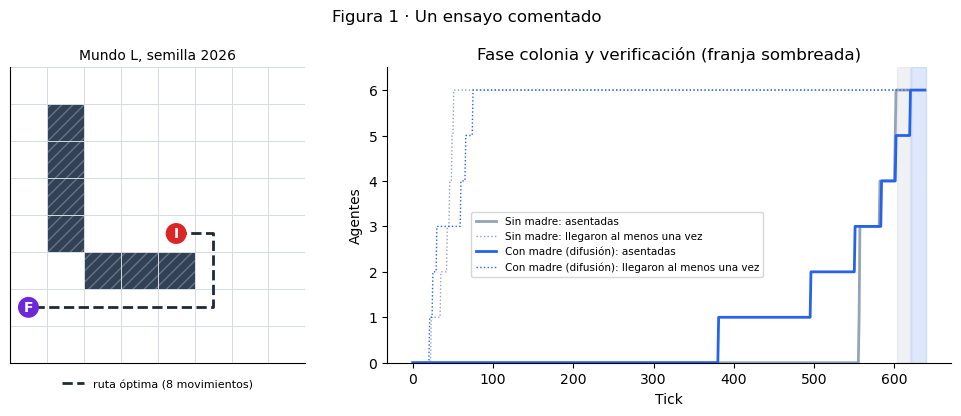

In [3]:
def dibujar_mundo(eje, feromona=None, titulo=""):
    """El mundo con el estilo del plano: obstáculos sombreados, I rojo, F morado y, si se da, la feromona."""
    eje.set_xlim(0, MUNDO.ancho)
    eje.set_ylim(MUNDO.alto, 0)
    eje.set_aspect("equal")
    eje.set_xticks([])
    eje.set_yticks([])
    if feromona is not None:
        valores = np.array(feromona).reshape(MUNDO.alto, MUNDO.ancho)
        mapa = LinearSegmentedColormap.from_list("f", ["#ffffff", "#bbf7d0", PLANO["feromona"]])
        eje.imshow(valores / max(valores.max(), 1e-9), cmap=mapa, vmin=0, vmax=1,
                   extent=(0, MUNDO.ancho, MUNDO.alto, 0), interpolation="nearest")
    for k in range(MUNDO.ancho + 1):
        eje.axvline(k, color=PLANO["rejilla"], lw=0.7)
    for k in range(MUNDO.alto + 1):
        eje.axhline(k, color=PLANO["rejilla"], lw=0.7)
    for x, y in MUNDO.obstaculos:
        eje.add_patch(Rectangle((x, y), 1, 1, facecolor=PLANO["obstaculo"], hatch="///", edgecolor="#64748b", lw=0))
    for celda, color, letra in ((MUNDO.inicio, PLANO["inicio"], "I"), (MUNDO.meta, PLANO["meta"], "F")):
        eje.text(celda[0] + 0.5, celda[1] + 0.5, letra, color="white", ha="center", va="center", weight="bold",
                 bbox=dict(boxstyle="circle,pad=0.25", fc=color, ec="none"))
    eje.set_title(titulo, fontsize=10)


def trazar(eje, ruta, **estilo):
    eje.plot([c[0] + 0.5 for c in ruta], [c[1] + 0.5 for c in ruta], **estilo)


fig, (izq, der) = plt.subplots(1, 2, figsize=(10, 4.2), gridspec_kw={"width_ratios": [1, 1.6]})
dibujar_mundo(izq, titulo=f"Mundo L, semilla {SEMILLA}")
trazar(izq, OPTIMA, color=PLANO["texto"], ls="--", lw=2, label=f"ruta óptima ({len(OPTIMA) - 1} movimientos)")
izq.legend(loc="upper center", bbox_to_anchor=(0.5, -0.02), fontsize=8, frameon=False)
for r, nombre, color in ((SIN, "Sin madre", COLOR["ausente"]), (CON, "Con madre (difusión)", COLOR["difusion"])):
    ticks = [f["tick"] for f in r.serie]
    der.plot(ticks, [f["asentadas"] for f in r.serie], color=color, lw=2, label=f"{nombre}: asentadas")
    der.plot(ticks, [f["llegaron"] for f in r.serie], color=color, lw=1, ls=":", label=f"{nombre}: llegaron al menos una vez")
    der.axvspan(r.ticks_asentadas, r.ticks_total, color=color, alpha=0.15)
der.set(xlabel="Tick", ylabel="Agentes", ylim=(0, N_AGENTES + 0.5),
        title="Fase colonia y verificación (franja sombreada)")
der.legend(fontsize=7.5, loc="center left", bbox_to_anchor=(0.14, 0.4))
fig.suptitle("Figura 1 · Un ensayo comentado")
fig.tight_layout()
fig.savefig(FIGURAS / "f5_un_ensayo.png")

**Qué mirar.** A la izquierda, la ruta óptima que calcula el BFS: es la vara con la que se mide a la colonia. A la derecha, cuántas agentes ya llegaron a la meta (punteada) y cuántas terminaron sus viajes y se asentaron (continua); la franja sombreada es la verificación. Fíjese en que **en este ensayo** la colonia sin madre termina antes que con madre y que las dos rutas verificadas son bastante más largas que la óptima (las razones están en la salida de arriba): **una corrida suelta no dice qué modo es mejor**. Para eso están las 240 corridas de la sección 4.

## 2. Feromona y trazos

El mapa de color es la **feromona al final del ensayo** (más verde, más rastro). Encima van los **trazos** de las 6 agentes durante toda la fase de colonia (líneas finas y transparentes: donde se ven más oscuras, pasaron más veces), la **ruta de la verificadora** y la **óptima**. Mismo mundo y misma semilla; solo cambia la madre.

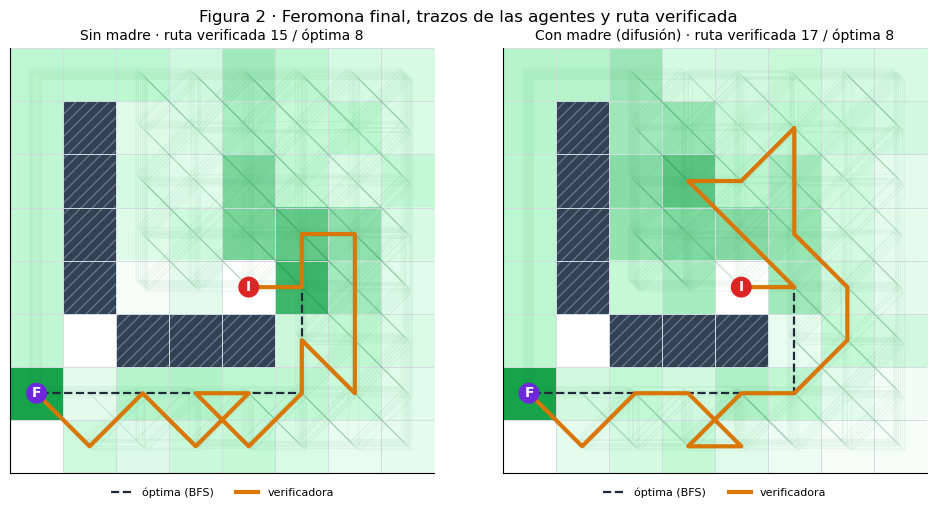

In [4]:
def trazos(r):
    """Recorrido de cada agente (sin la verificadora) a partir del historial del mundo."""
    por_agente = {}
    for _, i, celda in sorted(r.historial):
        if i <= N_AGENTES:
            por_agente.setdefault(i, [MUNDO.inicio]).append(celda)
    return por_agente


fig, ejes = plt.subplots(1, 2, figsize=(10, 5))
for eje, r, nombre in zip(ejes, (SIN, CON), ("Sin madre", "Con madre (difusión)")):
    dibujar_mundo(eje, feromona=r.feromona[-1],
                  titulo=f"{nombre} · ruta verificada {r.largo_verificado} / óptima {r.largo_optimo}")
    for k, ruta in enumerate(trazos(r).values()):
        desplazamiento = (k - N_AGENTES / 2) * 0.04  # separa un poco las agentes
        eje.plot([c[0] + 0.5 + desplazamiento for c in ruta], [c[1] + 0.5 + desplazamiento for c in ruta],
                 color=PLANO["agente"], lw=0.6, alpha=0.06)
    trazar(eje, OPTIMA, color=PLANO["texto"], ls="--", lw=1.6, label="óptima (BFS)")
    if r.ruta_verificada:
        trazar(eje, r.ruta_verificada, color=PLANO["verificadora"], lw=3, label="verificadora")
    eje.legend(loc="upper center", bbox_to_anchor=(0.5, -0.01), ncol=2, fontsize=8, frameon=False)
fig.suptitle("Figura 2 · Feromona final, trazos de las agentes y ruta verificada")
fig.tight_layout()
fig.savefig(FIGURAS / "f6_feromona_y_trazos.png")

**Qué mirar.** Si la franja verde más intensa coincide con la línea ámbar, la verificadora siguió el rastro más fuerte, que es lo que se espera. Si la línea ámbar se aleja de la óptima (punteada), la colonia reforzó un camino más largo. Cada viaje deja en cada celda de su ruta más feromona cuanto más corta es (255 ÷ largo; el total por viaje es casi el mismo, solo se concentra), y el rastro es la suma de los viajes menos la evaporación (1 % por tick): un camino largo muy recorrido puede acumular más que uno corto poco usado. Por qué la colonia se queda a veces con un camino largo **no está medido** (F-017 lo deja abierto). Los trazos muestran cuánto exploraron las agentes antes de asentarse. Ojo: el color se normaliza por el máximo de cada panel, así que la intensidad no se compara entre paneles.

## 3. Lo que sabe la madre

En los modos difusión y rescate (aquí, difusión) cada agente le envía a la madre **fragmentos de su mapa** (`FRAGMENTO`: qué celdas vio y cuáles son obstáculo). Los cuadros muestran el mapa de la madre en 8 momentos del ensayo con madre de las secciones 1 y 2.

**Regla de los cuadros, fijada antes de verlos:** 8 ticks equiespaciados desde el tick 0 hasta el primer tick en que el conocimiento alcanza su valor final. **Conocimiento** = fracción de celdas del mundo que la madre conoce **y** clasifica bien (libre u obstáculo).

Conocimiento final 100% en el tick 41; GIF de 17 cuadros en figuras/.


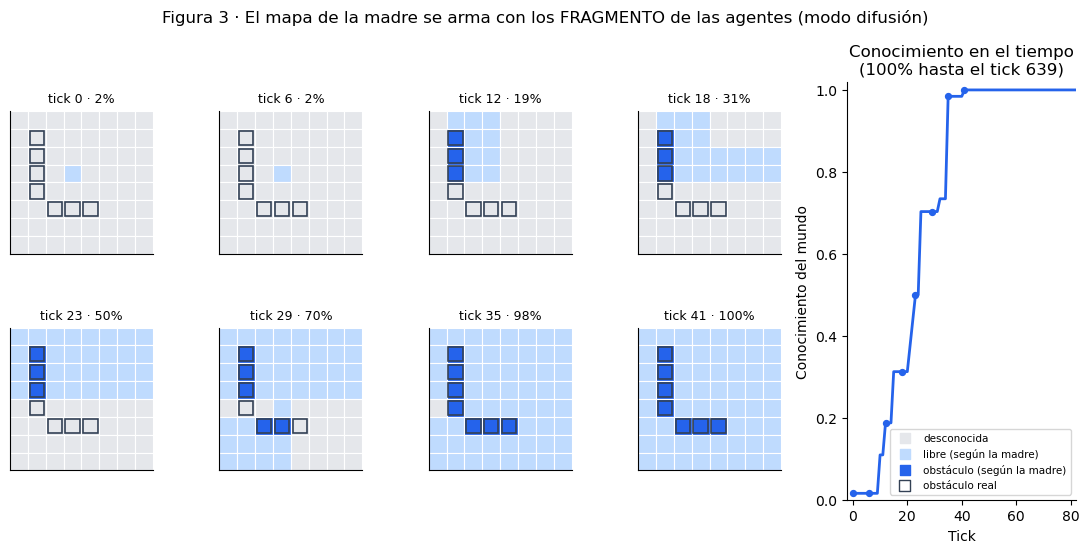

In [5]:
def celdas(bits):
    return {(k % MUNDO.ancho, k // MUNDO.ancho) for k in range(MUNDO.ancho * MUNDO.alto) if bits >> k & 1}


conocimiento = [f["conocimiento"] for f in CON.serie]
tope = conocimiento.index(conocimiento[-1])
TICKS = [round(tope * k / 7) for k in range(8)]
COLORES_MAPA = {"desconocida": "#e5e7eb", "libre": "#bfdbfe", "obstaculo": PLANO["madre"]}


def dibujar_madre(eje, tick):
    conocidas, obstaculos = (celdas(b) for b in CON.mapa_madre[tick])
    eje.set_xlim(0, MUNDO.ancho)
    eje.set_ylim(MUNDO.alto, 0)
    eje.set_aspect("equal")
    eje.set_xticks([])
    eje.set_yticks([])
    for y in range(MUNDO.alto):
        for x in range(MUNDO.ancho):
            estado = "obstaculo" if (x, y) in obstaculos else "libre" if (x, y) in conocidas else "desconocida"
            eje.add_patch(Rectangle((x, y), 1, 1, facecolor=COLORES_MAPA[estado], edgecolor="white", lw=0.8))
            if (x, y) in MUNDO.obstaculos:  # el mundo real, para comparar
                eje.add_patch(Rectangle((x + 0.1, y + 0.1), 0.8, 0.8, fill=False, edgecolor=PLANO["obstaculo"], lw=1.2))
    eje.set_title(f"tick {tick} · {conocimiento[tick]:.0%}", fontsize=9)


fig = plt.figure(figsize=(11, 5.6))
rejilla = fig.add_gridspec(2, 5, width_ratios=[1, 1, 1, 1, 1.6])
for k, tick in enumerate(TICKS):
    dibujar_madre(fig.add_subplot(rejilla[k // 4, k % 4]), tick)
curva = fig.add_subplot(rejilla[:, 4])
curva.plot(range(len(conocimiento)), conocimiento, color=PLANO["madre"], lw=2)
curva.scatter(TICKS, [conocimiento[t] for t in TICKS], color=PLANO["madre"], zorder=3, s=18)
curva.set(xlabel="Tick", ylabel="Conocimiento del mundo", ylim=(0, 1.02), xlim=(-2, 2 * tope),
          title=f"Conocimiento en el tiempo\n({CON.conocimiento:.0%} hasta el tick {CON.ticks_total})")
for estado, color in COLORES_MAPA.items():
    curva.scatter([], [], marker="s", s=60, color=color, label={"desconocida": "desconocida", "libre": "libre (según la madre)",
                                                                   "obstaculo": "obstáculo (según la madre)"}[estado])
curva.scatter([], [], marker="s", s=60, facecolor="none", edgecolor=PLANO["obstaculo"], label="obstáculo real")
curva.legend(fontsize=7.5, loc="lower right")
fig.suptitle("Figura 3 · El mapa de la madre se arma con los FRAGMENTO de las agentes (modo difusión)")
fig.tight_layout()
fig.savefig(FIGURAS / "f7_conocimiento_de_la_madre.png")

# El mismo mapa como animación (un cuadro cada 5 ticks hasta el tope y unos segundos de pausa al final).
fig_gif, eje_gif = plt.subplots(figsize=(3.6, 3.9))
cuadros_gif = list(range(0, tope + 1, 5)) + [tope] * 8
animacion = animation.FuncAnimation(fig_gif, lambda t: dibujar_madre(eje_gif, t), frames=cuadros_gif)
animacion.save(FIGURAS / "f7_conocimiento_de_la_madre.gif", writer=animation.PillowWriter(fps=8))
plt.close(fig_gif)
print(f"Conocimiento final {CON.conocimiento:.0%} en el tick {tope}; GIF de {len(cuadros_gif)} cuadros en figuras/.")

**Qué mirar.** El gris es lo que la madre todavía no sabe; el azul claro, lo que cree libre; el azul fuerte, lo que cree obstáculo. Los recuadros oscuros marcan los obstáculos **reales**: donde un recuadro cae sobre azul fuerte, la madre acertó. La curva muestra a qué ritmo aprende: casi todo llega en los primeros viajes, cuando las agentes todavía exploran; después solo confirman lo que ya se sabía. El GIF `figuras/f7_conocimiento_de_la_madre.gif` muestra lo mismo cuadro a cuadro.

## 4. Los modos de la madre

Resumen por condición (30 semillas cada una; intervalos de confianza de Wilson al 95 %).

In [6]:
columnas = ["escenario", "modo", "verificadas", "verificadas_ic95_bajo", "verificadas_ic95_alto",
            "ticks_media", "ticks_varianza", "razon_media", "bytes_agente_madre_media", "bytes_madre_agente_media"]
tabla = resumen_modos[columnas].copy()
tabla["bytes_madre"] = tabla.pop("bytes_agente_madre_media") + tabla.pop("bytes_madre_agente_media")
tabla.round(2)

,escenario,modo,verificadas,verificadas_ic95_bajo,verificadas_ic95_alto,ticks_media,ticks_varianza,razon_media,bytes_madre
0,L,ausente,21,0.52,0.83,465.47,20369.32,1.44,0.00
1,L,pista_de_baile,24,0.63,0.90,433.30,13984.41,1.67,4678.97
2,L,rescate,21,0.52,0.83,465.47,20369.32,1.44,4883.23
3,L,difusion,25,0.66,0.93,441.30,27752.41,1.58,6338.80
4,aleatorio,ausente,18,0.42,0.75,427.57,18925.18,1.28,0.00
5,aleatorio,pista_de_baile,25,0.66,0.93,390.33,12108.16,1.42,4239.87
6,aleatorio,rescate,18,0.42,0.75,427.57,18925.18,1.28,4488.10
7,aleatorio,difusion,25,0.66,0.93,417.23,25092.71,1.26,5949.30


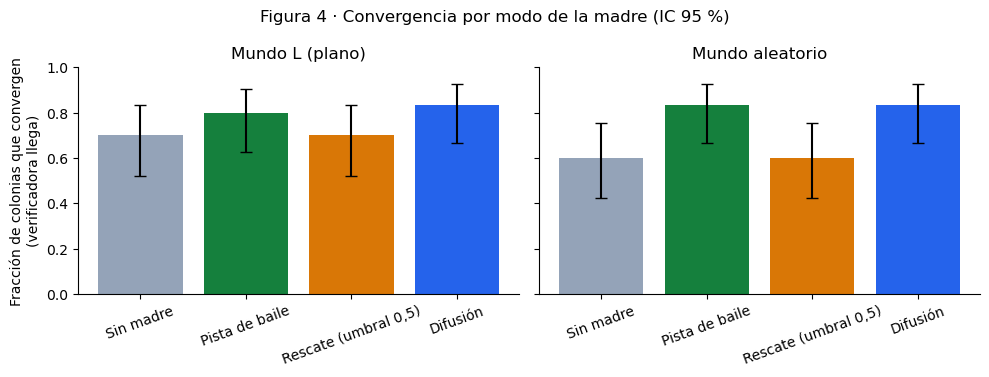

In [7]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for eje, (escenario, titulo) in zip(ejes, ESCENARIOS.items()):
    filas = resumen_modos.set_index("escenario").loc[escenario].set_index("modo").loc[MODOS]
    tasa = filas["verificadas_tasa"]
    error = [tasa - filas["verificadas_ic95_bajo"], filas["verificadas_ic95_alto"] - tasa]
    eje.bar([NOMBRE[m] for m in MODOS], tasa, yerr=error, capsize=4, color=[COLOR[m] for m in MODOS])
    eje.set_title(titulo)
    eje.set_ylim(0, 1)
    eje.tick_params(axis="x", rotation=20)
ejes[0].set_ylabel("Fracción de colonias que convergen\n(verificadora llega)")
fig.suptitle("Figura 4 · Convergencia por modo de la madre (IC 95 %)")
fig.tight_layout()
fig.savefig(FIGURAS / "f1_convergencia_por_modo.png")

**Qué mirar.** Las barras son la fracción de las 30 colonias que convergen; las rayas, el intervalo de confianza al 95 %. Si los intervalos de dos modos se solapan mucho, con 30 semillas no se puede decir que uno sea mejor. "Rescate (umbral 0,5)" sale igual a "sin madre" porque con ese umbral la madre no envía ningún rescate (sección 6).

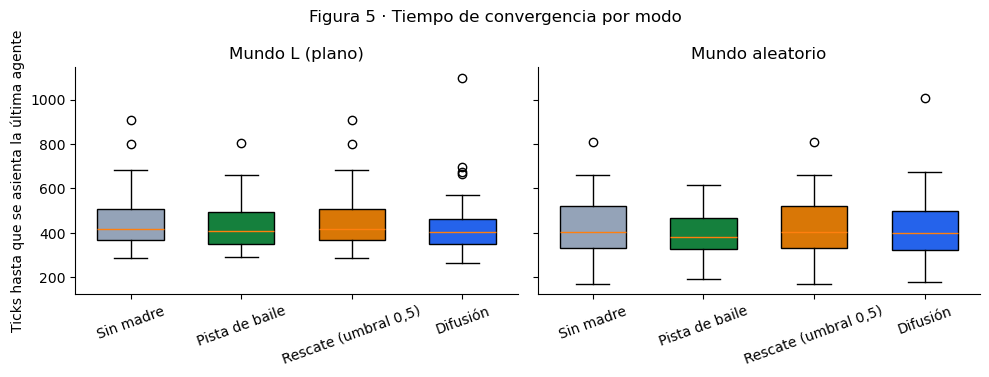

In [8]:
fig, ejes = plt.subplots(1, 2, figsize=(10, 3.8), sharey=True)
for eje, (escenario, titulo) in zip(ejes, ESCENARIOS.items()):
    datos = [modos[(modos.escenario == escenario) & (modos.modo == m)]["ticks_asentadas"].dropna() for m in MODOS]
    caja = eje.boxplot(datos, patch_artist=True, widths=0.6)
    for parche, m in zip(caja["boxes"], MODOS):
        parche.set_facecolor(COLOR[m])
    eje.set_xticks(range(1, 5), [NOMBRE[m] for m in MODOS], rotation=20)
    eje.set_title(titulo)
ejes[0].set_ylabel("Ticks hasta que se asienta la última agente")
fig.suptitle("Figura 5 · Tiempo de convergencia por modo")
fig.tight_layout()
fig.savefig(FIGURAS / "f2_tiempo_por_modo.png")

**Qué mirar.** Cada caja reúne los 30 tiempos de un modo: la raya del medio es la mediana y el alto de la caja, la dispersión. Una caja más baja es una colonia más rápida; una caja más corta, una colonia más predecible.

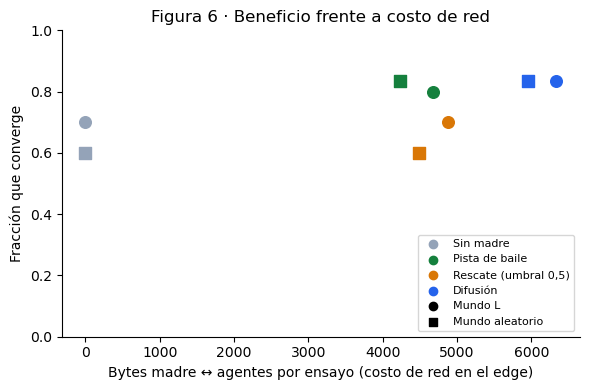

In [9]:
fig, eje = plt.subplots(figsize=(6, 4))
for escenario, marca in (("L", "o"), ("aleatorio", "s")):
    filas = resumen_modos[resumen_modos.escenario == escenario]
    for _, f in filas.iterrows():
        eje.scatter(f.bytes_agente_madre_media + f.bytes_madre_agente_media, f.verificadas_tasa,
                    color=COLOR[f.modo], marker=marca, s=70)
for m in MODOS:
    eje.scatter([], [], color=COLOR[m], label=NOMBRE[m])
eje.scatter([], [], color="k", marker="o", label="Mundo L")
eje.scatter([], [], color="k", marker="s", label="Mundo aleatorio")
eje.set_xlabel("Bytes madre ↔ agentes por ensayo (costo de red en el edge)")
eje.set_ylabel("Fracción que converge")
eje.set_ylim(0, 1)
eje.legend(fontsize=8, loc="lower right")
eje.set_title("Figura 6 · Beneficio frente a costo de red")
fig.tight_layout()
fig.savefig(FIGURAS / "f3_costo_de_red.png")

**Qué mirar.** Hacia la derecha cuesta más red (bytes entre la madre y las agentes por ensayo); hacia arriba converge más. Un modo que vale la pena está arriba y a la izquierda. Sin madre el costo es 0 por definición.

## 5. Costo de red

**Tamaño de cada mensaje.** Los dos formatos llevan la misma información cuantizada (`PROTOCOLO.md`); el binario es el que irá por radio. La línea roja es el máximo de un paquete ESP-NOW (250 bytes). Los tamaños se calculan con los codificadores del gemelo y un ejemplo típico de cada mensaje (`aco_gemelo/protocolo/tamanos.py`).

Binario: de 5 a 24 B; el JSON ocupa entre 9.6 y 27.2 veces más. En JSON no caben en un paquete ESP-NOW: MAPA, PERCEPCION.


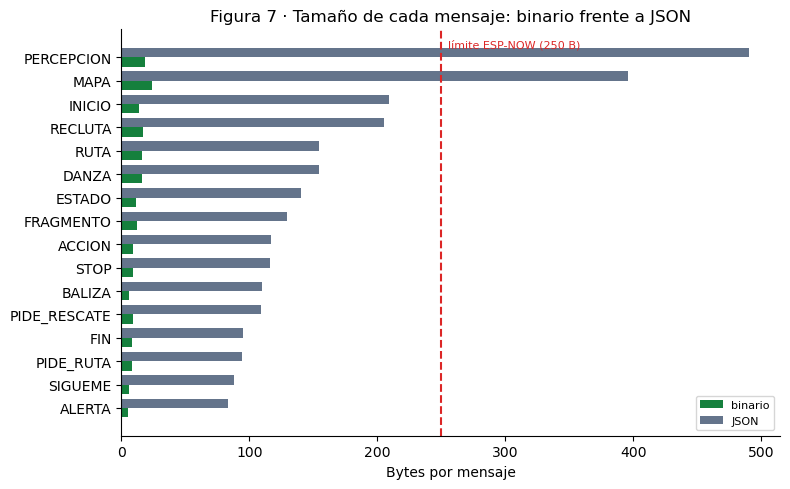

In [10]:
tabla_tamanos = pd.DataFrame(tamanos()).sort_values("json")
fig, eje = plt.subplots(figsize=(8, 5))
posiciones = np.arange(len(tabla_tamanos))
eje.barh(posiciones - 0.2, tabla_tamanos["binario"], height=0.4, color=PLANO["agente"], label="binario")
eje.barh(posiciones + 0.2, tabla_tamanos["json"], height=0.4, color=PLANO["suave"], label="JSON")
eje.axvline(LIMITE_ESP_NOW, color=PLANO["inicio"], lw=1.5, ls="--")
eje.text(LIMITE_ESP_NOW + 5, len(tabla_tamanos) - 0.6, "límite ESP-NOW (250 B)", color=PLANO["inicio"], fontsize=8)
eje.set_yticks(posiciones, tabla_tamanos["mensaje"])
eje.set_xlabel("Bytes por mensaje")
eje.legend(loc="lower right", fontsize=8)
eje.set_title("Figura 7 · Tamaño de cada mensaje: binario frente a JSON")
fig.tight_layout()
fig.savefig(FIGURAS / "f8_tamano_de_mensajes.png")
no_caben = tabla_tamanos[~tabla_tamanos["json_cabe_en_esp_now"]]["mensaje"].tolist()
print(f"Binario: de {tabla_tamanos.binario.min()} a {tabla_tamanos.binario.max()} B; el JSON ocupa entre "
      f"{tabla_tamanos.veces.min()} y {tabla_tamanos.veces.max()} veces más. "
      f"En JSON no caben en un paquete ESP-NOW: {', '.join(no_caben) or 'ninguno'}.")

**Qué mirar.** Toda barra verde muy por debajo de la línea roja cabe sobrada en un paquete ESP-NOW; las grises que pasan la línea no caben en JSON. Por eso, si el transporte es ESP-NOW, el formato tiene que ser binario (bloqueante B2 de `ESTADO-PREHARDWARE.md`). Con MQTT el JSON cabe, pero ocupa muchas veces más bytes (la cifra exacta, en la salida de la celda).

**Tráfico por familia.** Bytes por ensayo (media de 30 semillas, formato binario), apilados por familia de mensajes.

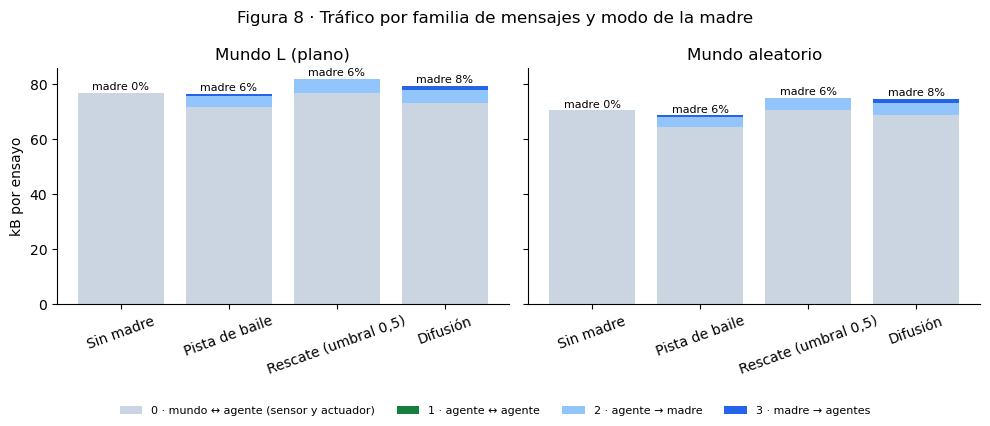

In [11]:
FAMILIAS = {"bytes_mundo_agente": ("0 · mundo ↔ agente (sensor y actuador)", "#cbd5e1"),
            "bytes_agente_agente": ("1 · agente ↔ agente", PLANO["agente"]),
            "bytes_agente_madre": ("2 · agente → madre", "#93c5fd"),
            "bytes_madre_agente": ("3 · madre → agentes", PLANO["madre"])}
fig, ejes = plt.subplots(1, 2, figsize=(10, 4.2), sharey=True)
for eje, (escenario, titulo) in zip(ejes, ESCENARIOS.items()):
    medias = modos[modos.escenario == escenario].groupby("modo")[list(FAMILIAS)].mean().loc[MODOS] / 1000
    abajo = np.zeros(len(MODOS))
    for columna, (etiqueta, color) in FAMILIAS.items():
        eje.bar([NOMBRE[m] for m in MODOS], medias[columna], bottom=abajo, color=color, label=etiqueta)
        abajo += medias[columna].to_numpy()
    for k, m in enumerate(MODOS):
        madre = medias.loc[m, "bytes_agente_madre"] + medias.loc[m, "bytes_madre_agente"]
        eje.text(k, abajo[k] + 1, f"madre {madre / abajo[k]:.0%}", ha="center", fontsize=8)
    eje.set_title(titulo)
    eje.tick_params(axis="x", rotation=20)
ejes[0].set_ylabel("kB por ensayo")
fig.legend(*ejes[0].get_legend_handles_labels(), loc="lower center", ncol=4, fontsize=8, frameon=False)
fig.suptitle("Figura 8 · Tráfico por familia de mensajes y modo de la madre")
fig.tight_layout(rect=(0, 0.07, 1, 1))
fig.savefig(FIGURAS / "f9_trafico_por_familia.png")

**Qué mirar.** Casi todo el tráfico es de la familia 0: la percepción y la acción de cada agente en cada tick. En el gemelo es el sensor y el actuador simulados; en la fase 2 (NetLogo) irá por la red, y en la fase 3 serán sensores reales sin radio. El porcentaje sobre cada barra es lo que agrega la madre. La familia 1 (agente ↔ agente) vale 0 porque `BALIZA`, `ALERTA` y `SIGUEME` todavía no están implementados.

## 6. ¿Reduce el rescate la varianza del tiempo de convergencia?

Con el umbral por defecto (0,5) el rescate nunca se dispara: sus resultados son idénticos a los de "sin madre".
El plan `rescate` barre el umbral (rezagada = experiencia menor que esa fracción del promedio de la colonia).

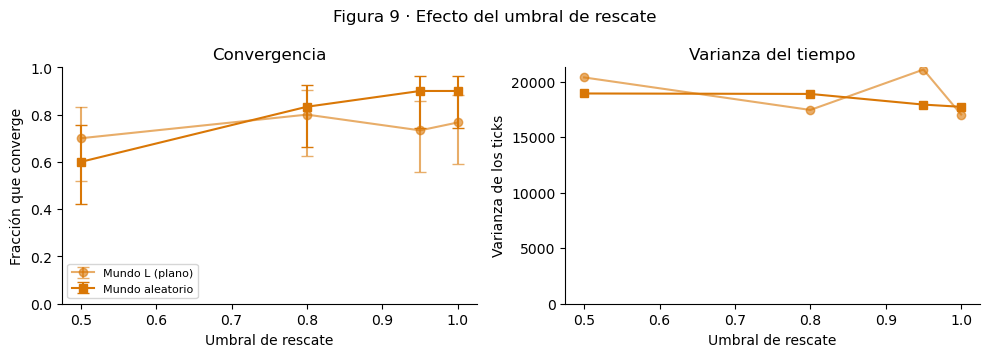

In [12]:
fig, (izq, der) = plt.subplots(1, 2, figsize=(10, 3.6))
for escenario, marca in (("L", "o-"), ("aleatorio", "s-")):
    filas = resumen_rescate[resumen_rescate.escenario == escenario].sort_values("umbral_rescate")
    tasa = filas["verificadas_tasa"]
    izq.errorbar(filas["umbral_rescate"], tasa, fmt=marca, capsize=4, color=COLOR["rescate"],
                 yerr=[tasa - filas["verificadas_ic95_bajo"], filas["verificadas_ic95_alto"] - tasa],
                 label=ESCENARIOS[escenario], alpha=0.6 if escenario == "L" else 1)
    der.plot(filas["umbral_rescate"], filas["ticks_varianza"], marca, color=COLOR["rescate"],
             label=ESCENARIOS[escenario], alpha=0.6 if escenario == "L" else 1)
izq.set(xlabel="Umbral de rescate", ylabel="Fracción que converge", ylim=(0, 1), title="Convergencia")
der.set(xlabel="Umbral de rescate", ylabel="Varianza de los ticks", title="Varianza del tiempo")
der.set_ylim(bottom=0)
izq.legend(fontsize=8)
fig.suptitle("Figura 9 · Efecto del umbral de rescate")
fig.tight_layout()
fig.savefig(FIGURAS / "f4_umbral_de_rescate.png")

**Qué mirar.** A la izquierda, si subir el umbral (rescatar a más agentes) hace converger a más colonias; a la derecha, si baja la varianza del tiempo, que es lo que afirma la hipótesis de `resumen.pdf`. Una curva de varianza que baja con el umbral apoyaría la hipótesis; las pruebas de abajo dicen si la bajada es más que ruido.

### Pruebas estadísticas

> **Advertencia de método:** estas pruebas se fijaron **después** de una mirada exploratoria a los mismos datos (F-018, que usó Levene centrada en la media). Por eso son **exploratorias, no confirmatorias**: para confirmar un efecto haría falta un experimento nuevo, con más semillas y las pruebas declaradas antes.

Para cada mundo se compara **sin madre** (que equivale a "sin rescate") con el **rescate a umbral 0,8, 0,95 y 1,0**:

- **Varianza del tiempo:** prueba de Brown-Forsythe (Levene centrada en la mediana), porque los tiempos no son normales.
- **Tiempo típico:** Mann-Whitney U, bilateral.
- **Tasa de convergencia:** prueba exacta de Fisher, bilateral.
- Como son 6 comparaciones por prueba, se usa **corrección de Bonferroni** (α = 0,05 / 6). La hipótesis de `resumen.pdf` se considera apoyada si la varianza con rescate es **menor** y la diferencia es significativa tras corregir.

In [13]:
filas = []
for escenario in ESCENARIOS:
    sin = modos[(modos.escenario == escenario) & (modos.modo == "ausente")]
    for umbral in (0.8, 0.95, 1.0):
        con = rescate[(rescate.escenario == escenario) & np.isclose(rescate.umbral_rescate, umbral)]
        t_sin, t_con = sin["ticks_asentadas"].dropna(), con["ticks_asentadas"].dropna()
        v_sin, v_con = int(sin["verificada"].sum()), int(con["verificada"].sum())
        filas.append({
            "escenario": escenario, "umbral": umbral,
            "varianza_sin": round(t_sin.var(ddof=0)), "varianza_con": round(t_con.var(ddof=0)),
            "p_varianza": levene(t_sin, t_con, center="median").pvalue,
            "p_tiempo": mannwhitneyu(t_sin, t_con).pvalue,
            "converge_sin": f"{v_sin}/{len(sin)}", "converge_con": f"{v_con}/{len(con)}",
            "p_convergencia": fisher_exact([[v_con, len(con) - v_con], [v_sin, len(sin) - v_sin]]).pvalue,
        })
pruebas = pd.DataFrame(filas)
for columna in ("p_varianza", "p_tiempo", "p_convergencia"):
    pruebas[columna + "_bonferroni"] = (pruebas[columna] * len(pruebas)).clip(upper=1)
pruebas.round(3)

,escenario,umbral,varianza_sin,varianza_con,p_varianza,p_tiempo,converge_sin,converge_con,p_convergencia,p_varianza_bonferroni,p_tiempo_bonferroni,p_convergencia_bonferroni
0,L,0.80,20369,17442,0.914,0.344,21/30,24/30,0.552,1.0,1.000,1.000
1,L,0.95,20369,21076,0.905,0.158,21/30,22/30,1.000,1.0,0.948,1.000
2,L,1.00,20369,17030,0.911,0.167,21/30,23/30,0.771,1.0,1.000,1.000
3,aleatorio,0.80,18925,18884,0.857,0.325,18/30,25/30,0.084,1.0,1.000,0.504
4,aleatorio,0.95,18925,17925,0.843,0.387,18/30,27/30,0.015,1.0,1.000,0.092
5,aleatorio,1.00,18925,17725,0.807,0.395,18/30,27/30,0.015,1.0,1.000,0.092


## 7. Conclusiones (calculadas a partir de los datos)

In [14]:
ALFA = 0.05
apoyos = pruebas[(pruebas.varianza_con < pruebas.varianza_sin) & (pruebas.p_varianza_bonferroni < ALFA)]
mejoras = pruebas[pruebas.p_convergencia_bonferroni < ALFA]
mejor = pruebas.loc[pruebas.p_convergencia.idxmin()]

print("Modos de la madre (Figura 4):")
for escenario in ESCENARIOS:
    filas = resumen_modos[resumen_modos.escenario == escenario].set_index("modo")
    texto = ", ".join(f"{NOMBRE[m].split(' (')[0].lower()} {int(filas.loc[m, 'verificadas'])}/30" for m in MODOS)
    print(f"  - {ESCENARIOS[escenario]}: {texto}.")
print()
print("Hipótesis de resumen.pdf (el rescate reduce la varianza del tiempo):")
if len(apoyos):
    print(f"  APOYADA en {len(apoyos)} de {len(pruebas)} comparaciones tras corregir por Bonferroni.")
else:
    print(f"  NO apoyada: en ninguna de las {len(pruebas)} comparaciones la varianza con rescate es menor "
          f"de forma significativa tras corregir (p de Brown-Forsythe corregido mínimo = "
          f"{pruebas.p_varianza_bonferroni.min():.2f}).")
print()
print("Convergencia con rescate frente a sin madre:")
if len(mejoras):
    print(f"  Mejora significativa tras corregir en {len(mejoras)} comparaciones.")
else:
    print(f"  Ninguna diferencia significativa tras corregir. La más fuerte: {ESCENARIOS[mejor.escenario]}, "
          f"umbral {mejor.umbral}: {mejor.converge_con} frente a {mejor.converge_sin} "
          f"(p = {mejor.p_convergencia:.3f} sin corregir; {mejor.p_convergencia_bonferroni:.2f} corregido).")
    print("  Para confirmarla o descartarla harían falta más semillas (≈ 100 por condición).")

Modos de la madre (Figura 4):
  - Mundo L (plano): sin madre 21/30, pista de baile 24/30, rescate 21/30, difusión 25/30.
  - Mundo aleatorio: sin madre 18/30, pista de baile 25/30, rescate 18/30, difusión 25/30.

Hipótesis de resumen.pdf (el rescate reduce la varianza del tiempo):
  NO apoyada: en ninguna de las 6 comparaciones la varianza con rescate es menor de forma significativa tras corregir (p de Brown-Forsythe corregido mínimo = 1.00).

Convergencia con rescate frente a sin madre:
  Ninguna diferencia significativa tras corregir. La más fuerte: Mundo aleatorio, umbral 0.95: 27/30 frente a 18/30 (p = 0.015 sin corregir; 0.09 corregido).
  Para confirmarla o descartarla harían falta más semillas (≈ 100 por condición).
